# Dental Caries Training (AlphaDent and DENTEX)


In [ ]:
# Mount Google Drive so Colab can read the manifests/images and save model outputs.
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
from pathlib import Path

MODEL_TRAINING_DIR = Path('/content/drive/MyDrive/Research/Model_Training')
ALPHADENT_ROOT = Path('/content/drive/MyDrive/Research/Model_Training/Caries_Dataset/Caries_Intraoral')
DENTEX_ROOT = Path('/content/drive/MyDrive/Research/Model_Training/Caries_Dataset/Caries_Xray')

PP1_FINAL_DIR = Path('/content/drive/MyDrive/Research/Model_Training/Caries_Dataset/PP1_Final')
ALPHA_MANIFEST = PP1_FINAL_DIR / 'Intraoral/manifests/alphadent_binary.csv'
DENTEX_MANIFEST = PP1_FINAL_DIR / 'Xray/manifests/dentex_binary_3way.csv'

OUTPUT_ROOT = MODEL_TRAINING_DIR / 'outputs/caries_EfficientNetB0'

print('Model-training folder exists:', MODEL_TRAINING_DIR.exists(), MODEL_TRAINING_DIR)
print('AlphaDent source exists:', ALPHADENT_ROOT.exists(), ALPHADENT_ROOT)
print('DENTEX source exists:', DENTEX_ROOT.exists(), DENTEX_ROOT)
print('AlphaDent manifest exists:', ALPHA_MANIFEST.exists(), ALPHA_MANIFEST)
print('DENTEX manifest exists:', DENTEX_MANIFEST.exists(), DENTEX_MANIFEST)

assert ALPHA_MANIFEST.is_file(), 'AlphaDent manifest is missing. Update PP1_FINAL_DIR.'
assert DENTEX_MANIFEST.is_file(), 'DENTEX manifest is missing. Update PP1_FINAL_DIR.'
assert MODEL_TRAINING_DIR.is_dir(), (
    'Shared Model_Training folder is not visible under MyDrive. Add a Drive shortcut '
    'to My Drive or update MODEL_TRAINING_DIR to the path visible in Colab.'
)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)


Model-training folder exists: True /content/drive/MyDrive/Research/Model_Training
AlphaDent source exists: True /content/drive/MyDrive/Research/Model_Training/Caries_Dataset/Caries_Intraoral
DENTEX source exists: True /content/drive/MyDrive/Research/Model_Training/Caries_Dataset/Caries_Xray
AlphaDent manifest exists: True /content/drive/MyDrive/Research/Model_Training/Caries_Dataset/PP1_Final/Intraoral/manifests/alphadent_binary.csv
DENTEX manifest exists: True /content/drive/MyDrive/Research/Model_Training/Caries_Dataset/PP1_Final/Xray/manifests/dentex_binary_3way.csv


## Load and audit the existing manifests

The AlphaDent split is patient-level. DENTEX has no patient IDs in the source annotation JSON, so its split is image-level. This cell confirms the expected columns and split labels, checks split overlap, and resolves image paths for this Drive account.

In [ ]:
import pandas as pd
import numpy as np
from PIL import Image

alpha_df = pd.read_csv(ALPHA_MANIFEST)
dentex_df = pd.read_csv(DENTEX_MANIFEST)

required = {'image_id', 'image_path', 'split', 'target', 'target_name'}
for name, frame in [('AlphaDent', alpha_df), ('DENTEX', dentex_df)]:
    missing = required - set(frame.columns)
    assert not missing, f'{name} manifest missing columns: {missing}'
    assert frame['image_id'].is_unique, f'{name} has duplicate image_id rows'
    assert frame['target'].isin([0, 1]).all(), f'{name} has targets outside 0/1'
    print(f'\n{name} split/class counts:')
    print(pd.crosstab(frame['split'], frame['target_name']))

assert set(alpha_df['split']) == {'train', 'validation', 'test'}
assert set(dentex_df['split']) == {'train', 'validation', 'test_internal'}

if 'patient_id' in alpha_df.columns:
    patients_by_split = {
        s: set(alpha_df.loc[alpha_df['split'] == s, 'patient_id'].dropna().astype(str))
        for s in alpha_df['split'].unique()
    }
    for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
        assert not (patients_by_split[a] & patients_by_split[b]), f'AlphaDent patient overlap: {a}/{b}'
    print('\nAlphaDent patient split overlap: none')

# DENTEX patient IDs are absent/blank in the COCO source; do not treat image IDs as patient IDs.
if 'patient_id' not in dentex_df.columns or dentex_df['patient_id'].isna().all():
    print('DENTEX split is image-level; patient IDs are not available.')



AlphaDent split/class counts:
target_name  caries  no_caries
split                         
test            138         63
train           708        328
validation       64         19

DENTEX split/class counts:
target_name    caries  no_caries
split                           
test_internal      78          7
train             442         37
validation        130         11

AlphaDent patient split overlap: none
DENTEX split is image-level; patient IDs are not available.


In [ ]:
# Resolve image paths for this account. Existing paths work as-is. If a teammate has
# moved the source folder, the original path suffix after Caries_Intraoral/Caries_Xray
# is appended to the configured team dataset root.
def resolve_image_path(raw_path, dataset_name):
    raw = Path(str(raw_path))
    if raw.is_file():
        return str(raw)

    if dataset_name == 'AlphaDent':
        root, marker = ALPHADENT_ROOT, 'Caries_Intraoral'
    elif dataset_name == 'DENTEX':
        root, marker = DENTEX_ROOT, 'Caries_Xray'
    else:
        raise ValueError(f'Unknown dataset: {dataset_name}')

    parts = raw.parts
    if marker in parts:
        suffix = parts[parts.index(marker) + 1:]
        candidate = root.joinpath(*suffix)
        if candidate.is_file():
            return str(candidate)

    # Last fallback: find a unique file with the same basename under the configured root.
    matches = list(root.rglob(raw.name)) if root.is_dir() else []
    if len(matches) == 1:
        return str(matches[0])

    raise FileNotFoundError(
        f'Could not resolve {raw_path}. Update {dataset_name} root in the path cell.'
    )

alpha_df['resolved_path'] = alpha_df['image_path'].map(lambda p: resolve_image_path(p, 'AlphaDent'))
dentex_df['resolved_path'] = dentex_df['image_path'].map(lambda p: resolve_image_path(p, 'DENTEX'))

for name, frame in [('AlphaDent', alpha_df), ('DENTEX', dentex_df)]:
    missing = [p for p in frame['resolved_path'] if not Path(p).is_file()]
    assert not missing, f'{name}: missing images: {missing[:5]}'
    print(f'{name}: resolved {len(frame)} image paths.')


AlphaDent: resolved 1320 image paths.
DENTEX: resolved 705 image paths.


## Imports and image pipeline

The first baseline uses 224 × 224 RGB inputs and does not augment images. EfficientNetB0 includes its own input rescaling layer, so the images are resized but not divided by 255 here. Training examples receive balanced sample weights; validation metrics use the natural class distribution.

In [ ]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import json

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS_FROZEN = 15
AUTOTUNE = tf.data.AUTOTUNE
tf.keras.utils.set_random_seed(SEED)

print('TensorFlow:', tf.__version__)
print('GPU devices:', tf.config.list_physical_devices('GPU'))

def make_dataset(frame, training=False):
    """Create a tf.data pipeline from a manifest subset."""
    paths = frame['resolved_path'].astype(str).to_numpy()
    labels = frame['target'].astype('int32').to_numpy()

    if training:
        counts = np.bincount(labels, minlength=2)
        assert np.all(counts > 0), f'Training subset must contain both classes; counts={counts}'
        # Balanced class weights: useful for DENTEX's lower number of no-caries images.
        sample_weights = np.where(
            labels == 0,
            len(labels) / (2.0 * counts[0]),
            len(labels) / (2.0 * counts[1]),
        ).astype('float32')
        ds = tf.data.Dataset.from_tensor_slices((paths, labels, sample_weights))
    else:
        ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def decode_and_resize(path, label, sample_weight=None):
        image_bytes = tf.io.read_file(path)
        image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, IMG_SIZE)
        label = tf.reshape(tf.cast(label, tf.float32), [1])
        if sample_weight is not None:
            return image, label, sample_weight
        return image, label

    ds = ds.map(decode_and_resize, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

def get_train_val(frame):
    """Return only train and validation data. Test rows are intentionally omitted."""
    train_rows = frame.loc[frame['split'] == 'train'].copy()
    val_rows = frame.loc[frame['split'] == 'validation'].copy()
    assert len(train_rows) and len(val_rows)
    train_ds = make_dataset(train_rows, training=True)
    val_ds = make_dataset(val_rows, training=False)
    return train_rows, val_rows, train_ds, val_ds


TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## EfficientNetB0 model and training helper

The model outputs one probability: `0` means no caries and `1` means caries. It first trains with the pretrained feature extractor frozen. The best checkpoint is selected by validation loss. A backup callback helps restore an interrupted fit when the same training cell is rerun in the same Colab Drive environment.

In [ ]:
def build_model():
    """Build a binary image classifier with an ImageNet-pretrained EfficientNetB0."""
    backbone = keras.applications.EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_shape=(*IMG_SIZE, 3),
    )
    backbone.trainable = False

    inputs = keras.Input(shape=(*IMG_SIZE, 3), name='image')
    features = backbone(inputs, training=False)
    features = keras.layers.GlobalAveragePooling2D()(features)
    features = keras.layers.Dropout(0.30)(features)
    outputs = keras.layers.Dense(1, activation='sigmoid', name='caries_probability')(features)
    return keras.Model(inputs, outputs, name='efficientnetb0_binary_caries')

def compile_model(model, learning_rate):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=[
            'accuracy',
            keras.metrics.AUC(name='roc_auc'),
            keras.metrics.AUC(name='pr_auc', curve='PR'),
            keras.metrics.Precision(name='precision'),
            keras.metrics.Recall(name='recall'),
        ],
    )

def train_frozen(frame, dataset_name):
    """Train one dataset model using train/validation rows only."""
    output_dir = OUTPUT_ROOT / dataset_name
    output_dir.mkdir(parents=True, exist_ok=True)
    train_rows, val_rows, train_ds, val_ds = get_train_val(frame)

    model = build_model()
    compile_model(model, learning_rate=1e-3)

    callbacks = [
        keras.callbacks.ModelCheckpoint(
            filepath=str(output_dir / 'best_frozen.keras'),
            monitor='val_loss',
            save_best_only=True,
            verbose=1,
        ),
        keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=4, restore_best_weights=True, verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.2, patience=2, min_lr=1e-6, verbose=1,
        ),
        keras.callbacks.BackupAndRestore(backup_dir=str(output_dir / 'fit_backup')),
    ]

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS_FROZEN,
        callbacks=callbacks,
        verbose=1,
    )
    pd.DataFrame(history.history).to_csv(output_dir / 'frozen_history.csv', index=False)
    model.save(output_dir / 'last_frozen.keras')
    print(f'Best frozen checkpoint: {output_dir / "best_frozen.keras"}')
    return model, history, output_dir


## Train the AlphaDent model

It uses AlphaDent `train` and `validation` rows only. The AlphaDent `test` rows are not passed to `model.fit`.

In [ ]:
alpha_model, alpha_history, alpha_output_dir = train_frozen(alpha_df, 'AlphaDent')


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 462ms/step - accuracy: 0.4825 - loss: 0.7691 - pr_auc: 0.6680 - precision: 0.6440 - recall: 0.5052 - roc_auc: 0.4806
Epoch 1: val_loss improved from None to 0.71255, saving model to /content/drive/MyDrive/Research/Model_Training/outputs/PP1/AlphaDent/best_frozen.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Research/Model_Training/outputs/PP1/AlphaDent/best_frozen.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 499s 1s/step - accuracy: 0.5164 - loss: 0.7257 - pr_auc: 0.7093 - precision: 0.6865 - recall: 0.5381 - roc_auc: 0.5323 - val_accuracy: 0.4940 - val_loss: 0.7125 - val_pr_auc: 0.7934 - val_precision: 0.7895 - val_recall: 0.4688 - val_roc_auc: 0.5979 - learning_rate: 0.0010
Epoch 2/15
64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.5796 - loss: 0.6544 - pr_auc: 0.8052 - precision: 0.7817 - recall: 0.5384 - roc_auc: 0.6567
Epoch 2: val_loss improved from 0.71255 to 0.61464, saving m

## 8. Train the DENTEX model

It uses DENTEX `train` and `validation` rows only. DENTEX `test_internal` is not passed to `model.fit`.

In [ ]:
dentex_model, dentex_history, dentex_output_dir = train_frozen(dentex_df, 'DENTEX')


Epoch 1/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 606ms/step - accuracy: 0.3729 - loss: 0.7831 - pr_auc: 0.9015 - precision: 0.9068 - recall: 0.3479 - roc_auc: 0.4557
Epoch 1: val_loss improved from None to 0.54369, saving model to /content/drive/MyDrive/Research/Model_Training/outputs/PP1/DENTEX/best_frozen.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Research/Model_Training/outputs/PP1/DENTEX/best_frozen.keras
30/30 ━━━━━━━━━━━━━━━━━━━━ 255s 3s/step - accuracy: 0.4802 - loss: 0.7595 - pr_auc: 0.9053 - precision: 0.9106 - recall: 0.4842 - roc_auc: 0.4455 - val_accuracy: 0.8865 - val_loss: 0.5437 - val_pr_auc: 0.9385 - val_precision: 0.9385 - val_recall: 0.9385 - val_roc_auc: 0.5902 - learning_rate: 0.0010
Epoch 2/15
29/30 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7051 - loss: 0.7336 - pr_auc: 0.9189 - precision: 0.9440 - recall: 0.7258 - roc_auc: 0.6022
Epoch 2: val_loss did not improve from 0.54369
30/30 ━━━━━━━━━━━━━━━━━━━━ 61s 541ms/step - accuracy: 0.6868 - loss: 0

In [ ]:
print([
    (name, type(value).__name__)
    for name, value in globals().copy().items()
    if "train" in name.lower()
])

[('MODEL_TRAINING_DIR', 'PosixPath'), ('get_train_val', 'function'), ('train_frozen', 'function')]


In [ ]:
import inspect

print("Arguments:", inspect.signature(get_train_val))
print(inspect.getsource(get_train_val))

Arguments: (frame)
def get_train_val(frame):
    """Return only train and validation data. Test rows are intentionally omitted."""
    train_rows = frame.loc[frame['split'] == 'train'].copy()
    val_rows = frame.loc[frame['split'] == 'validation'].copy()
    assert len(train_rows) and len(val_rows)
    train_ds = make_dataset(train_rows, training=True)
    val_ds = make_dataset(val_rows, training=False)
    return train_rows, val_rows, train_ds, val_ds



In [ ]:
[
    (name, value.shape)
    for name, value in globals().copy().items()
    if isinstance(value, pd.DataFrame)
]

[('alpha_df', (1320, 7)), ('dentex_df', (705, 7)), ('frame', (705, 7))]

In [ ]:
train_rows, val_rows, train_ds, val_ds = get_train_val(alpha_df)

# Check validation images (no training augmentation)
for images, labels in val_ds.take(1):
    print("image range:",
          float(tf.reduce_min(images)),
          float(tf.reduce_max(images)))
    print("labels:",
          tf.unique(tf.cast(tf.reshape(labels, [-1]), tf.int32))[0].numpy())

image range: 0.0 255.0
labels: [0 1]


In [ ]:
alpha_train_rows, alpha_val_rows, alpha_train_ds, alpha_val_ds = get_train_val(alpha_df)
dentex_train_rows, dentex_val_rows, dentex_train_ds, dentex_val_ds = get_train_val(dentex_df)

for name, ds, val_rows in [
    ("AlphaDent", alpha_val_ds, alpha_val_rows),
    ("DENTEX", dentex_val_ds, dentex_val_rows),
]:
    for images, labels in ds.take(1):
        print(
            name,
            "| image range:",
            float(tf.reduce_min(images)),
            "to",
            float(tf.reduce_max(images)),
            "| validation label counts:",
            val_rows["target"].value_counts().sort_index().to_dict(),
        )

AlphaDent | image range: 0.0 to 255.0 | validation label counts: {0: 19, 1: 64}
DENTEX | image range: 0.0 to 255.0 | validation label counts: {0: 11, 1: 130}


In [ ]:
for name, rows in [
    ("AlphaDent", alpha_val_rows),
    ("DENTEX", dentex_val_rows),
]:
    print(f"\n{name}")
    print(rows.groupby(["target", "target_name"]).size())


AlphaDent
target  target_name
0       no_caries      19
1       caries         64
dtype: int64

DENTEX
target  target_name
0       no_caries       11
1       caries         130
dtype: int64


In [ ]:
train_rows, val_rows, train_ds, val_ds = get_train_val(dentex_df)

# Check validation images (no training augmentation)
for images, labels in val_ds.take(1):
    print("image range:",
          float(tf.reduce_min(images)),
          float(tf.reduce_max(images)))
    print("labels:",
          tf.unique(tf.cast(tf.reshape(labels, [-1]), tf.int32))[0].numpy())

image range: 0.0 255.0
labels: [1]


## 9. Optional fine-tuning

After reviewing the frozen models' validation results, you may fine-tune the last EfficientNet layers using a much lower learning rate. This is optional. Validation is used for early stopping; do not select the model based on either test split.

In [ ]:
def fine_tune(model, frame, dataset_name, unfreeze_last=30, epochs=8):
    """Fine-tune only the top backbone layers; keep BatchNorm layers frozen."""
    output_dir = OUTPUT_ROOT / dataset_name
    _, _, train_ds, val_ds = get_train_val(frame)

    backbone = model.get_layer('efficientnetb0')
    backbone.trainable = True
    cutoff = max(0, len(backbone.layers) - unfreeze_last)
    for layer in backbone.layers[:cutoff]:
        layer.trainable = False
    for layer in backbone.layers:
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False

    compile_model(model, learning_rate=1e-5)
    callbacks = [
        keras.callbacks.ModelCheckpoint(
            filepath=str(output_dir / 'best_finetuned.keras'),
            monitor='val_loss', save_best_only=True, verbose=1,
        ),
        keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=3, restore_best_weights=True, verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.2, patience=2, min_lr=1e-7, verbose=1,
        ),
    ]
    history = model.fit(
        train_ds, validation_data=val_ds, epochs=epochs,
        callbacks=callbacks, verbose=1,
    )
    pd.DataFrame(history.history).to_csv(output_dir / 'finetune_history.csv', index=False)
    model.save(output_dir / 'last_finetuned.keras')
    return model, history

# Uncomment and run only after reviewing the frozen-model validation results:
# alpha_model, alpha_finetune_history = fine_tune(alpha_model, alpha_df, 'AlphaDent')
# dentex_model, dentex_finetune_history = fine_tune(dentex_model, dentex_df, 'DENTEX')


In [ ]:
alpha_checkpoint = OUTPUT_ROOT / "AlphaDent" / "best_frozen.keras"
print("Checkpoint exists:", alpha_checkpoint.exists())

alpha_model = keras.models.load_model(alpha_checkpoint)
alpha_model, alpha_finetune_history = fine_tune(
    alpha_model, alpha_df, "AlphaDent"
)

Checkpoint exists: True
Epoch 1/8
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 281ms/step - accuracy: 0.6418 - loss: 0.6630 - pr_auc: 0.7900 - precision: 0.7762 - recall: 0.6524 - roc_auc: 0.6642
Epoch 1: val_loss improved from None to 0.63124, saving model to /content/drive/MyDrive/Research/Model_Training/outputs/PP1/AlphaDent/best_finetuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Research/Model_Training/outputs/PP1/AlphaDent/best_finetuned.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 214s 681ms/step - accuracy: 0.6486 - loss: 0.6297 - pr_auc: 0.8213 - precision: 0.7966 - recall: 0.6525 - roc_auc: 0.6952 - val_accuracy: 0.6506 - val_loss: 0.6312 - val_pr_auc: 0.8225 - val_precision: 0.8302 - val_recall: 0.6875 - val_roc_auc: 0.6361 - learning_rate: 1.0000e-05
Epoch 2/8
64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.6848 - loss: 0.6007 - pr_auc: 0.8594 - precision: 0.8101 - recall: 0.7046 - roc_auc: 0.7387
Epoch 2: val_loss did not improve from 0.63124
65/65 ━━━━━━━━━━━━━━━━━━━━ 14

In [ ]:
dentex_checkpoint = OUTPUT_ROOT / "DENTEX" / "best_frozen.keras"
print("Checkpoint exists:", dentex_checkpoint.exists())

dentex_model = keras.models.load_model(dentex_checkpoint)
dentex_model, dentex_finetune_history = fine_tune(
    dentex_model, dentex_df, "DENTEX"
)

Checkpoint exists: True
Epoch 1/8
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 609ms/step - accuracy: 0.7591 - loss: 0.6573 - pr_auc: 0.9674 - precision: 0.9555 - recall: 0.7720 - roc_auc: 0.7446
Epoch 1: val_loss improved from None to 0.59082, saving model to /content/drive/MyDrive/Research/Model_Training/outputs/PP1/DENTEX/best_finetuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Research/Model_Training/outputs/PP1/DENTEX/best_finetuned.keras
30/30 ━━━━━━━━━━━━━━━━━━━━ 118s 2s/step - accuracy: 0.7453 - loss: 0.6636 - pr_auc: 0.9510 - precision: 0.9494 - recall: 0.7647 - roc_auc: 0.6508 - val_accuracy: 0.7801 - val_loss: 0.5908 - val_pr_auc: 0.9398 - val_precision: 0.9541 - val_recall: 0.8000 - val_roc_auc: 0.6087 - learning_rate: 1.0000e-05
Epoch 2/8
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6873 - loss: 0.7062 - pr_auc: 0.9348 - precision: 0.9430 - recall: 0.7041 - roc_auc: 0.6307
Epoch 2: val_loss did not improve from 0.59082
30/30 ━━━━━━━━━━━━━━━━━━━━ 95s 458ms/s

## 10. Plot training and validation curves

Use these curves to inspect learning and overfitting. Do not use test performance to decide whether to fine-tune.

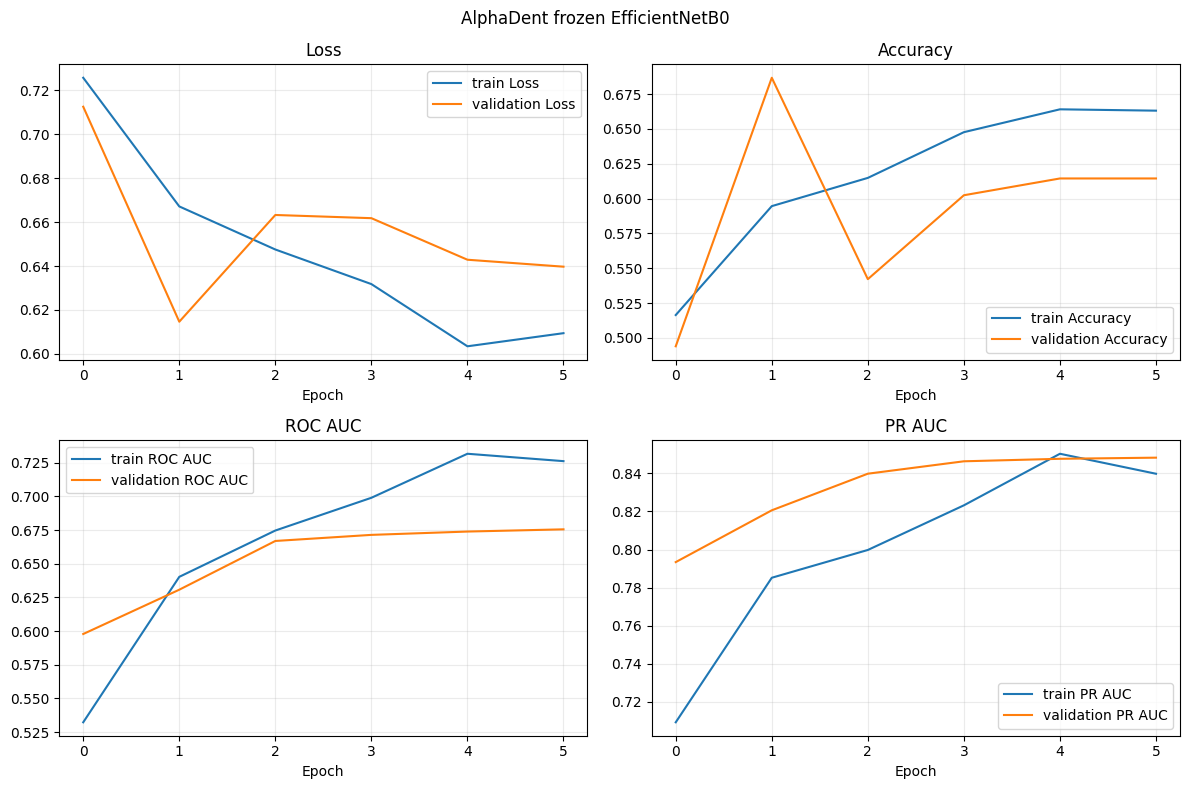

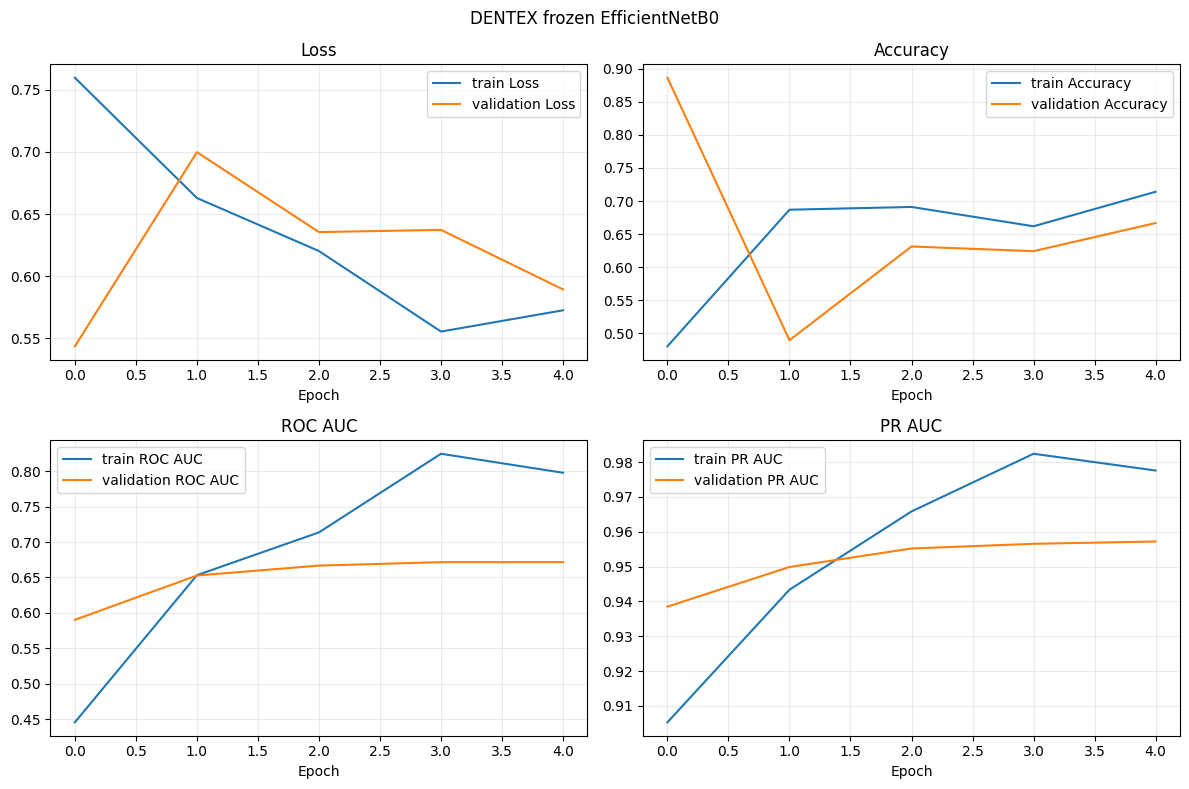

In [ ]:
def plot_history(history, title):
    metrics = [('loss', 'Loss'), ('accuracy', 'Accuracy'), ('roc_auc', 'ROC AUC'), ('pr_auc', 'PR AUC')]
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, (key, label) in zip(axes.ravel(), metrics):
        if key in history.history:
            ax.plot(history.history[key], label=f'train {label}')
            val_key = f'val_{key}'
            if val_key in history.history:
                ax.plot(history.history[val_key], label=f'validation {label}')
            ax.set_title(label)
            ax.set_xlabel('Epoch')
            ax.legend()
            ax.grid(True, alpha=0.25)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

plot_history(alpha_history, 'AlphaDent frozen EfficientNetB0')
plot_history(dentex_history, 'DENTEX frozen EfficientNetB0')


## 11. Save a run record

This records the manifest names, seed, image size, batch size, and split counts beside the checkpoints. It does not include patient identifiers.

In [ ]:
def write_run_record(dataset_name, frame, output_dir):
    record = {
        'dataset': dataset_name,
        'task': 'binary image-level caries classification',
        'architecture': 'ImageNet EfficientNetB0',
        'seed': SEED,
        'image_size': list(IMG_SIZE),
        'batch_size': BATCH_SIZE,
        'frozen_epochs_max': EPOCHS_FROZEN,
        'manifest': str(ALPHA_MANIFEST if dataset_name == 'AlphaDent' else DENTEX_MANIFEST),
        'split_counts': frame['split'].value_counts().to_dict(),
        'class_counts': pd.crosstab(frame['split'], frame['target_name']).to_dict(),
        'test_used_during_training': False,
    }
    with open(output_dir / 'run_record.json', 'w') as f:
        json.dump(record, f, indent=2)

write_run_record('AlphaDent', alpha_df, alpha_output_dir)
write_run_record('DENTEX', dentex_df, dentex_output_dir)
print('Run records saved beside model outputs.')


Run records saved beside model outputs.


## 12. Final test evaluation — run once after model choices are locked

Do not run this cell while you are still choosing architecture, epochs, preprocessing, or thresholds. First finish validation-based decisions, then run the final test evaluation once and save the metrics. AlphaDent uses `test`; DENTEX uses `test_internal`. The separate DENTEX 250-image labels are not loaded here.

In [ ]:
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, average_precision_score
)

def final_test_evaluation(model, frame, dataset_name, threshold=0.5):
    """Evaluate a locked model once on its held-out internal test split."""
    test_name = 'test' if dataset_name == 'AlphaDent' else 'test_internal'
    test_rows = frame.loc[frame['split'] == test_name].copy()
    assert len(test_rows) > 0, f'No {test_name} rows for {dataset_name}'

    # Build test batches only inside this final-evaluation function.
    test_ds = make_dataset(test_rows, training=False)
    y_true = test_rows['target'].astype(int).to_numpy()
    probabilities = model.predict(test_ds, verbose=1).ravel()
    y_pred = (probabilities >= threshold).astype(int)

    print(f'\n{dataset_name} final test results at threshold={threshold:.2f}')
    print('Confusion matrix [[TN, FP], [FN, TP]]:')
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))
    print(classification_report(
        y_true, y_pred, labels=[0, 1],
        target_names=['no_caries', 'caries'], zero_division=0,
    ))
    if len(np.unique(y_true)) == 2:
        print('ROC AUC:', round(roc_auc_score(y_true, probabilities), 4))
        print('Average precision / PR AUC:', round(average_precision_score(y_true, probabilities), 4))

    output_dir = OUTPUT_ROOT / dataset_name
    results = pd.DataFrame({
        'image_id': test_rows['image_id'].to_numpy(),
        'target': y_true,
        'probability_caries': probabilities,
        'predicted_target': y_pred,
        'threshold': threshold,
    })
    results.to_csv(output_dir / 'final_test_predictions.csv', index=False)
    print('Per-image predictions saved to:', output_dir / 'final_test_predictions.csv')

# Keep False while training/tuning. After locking both models and decisions,
# change to True and run this cell once for final reporting.
RUN_FINAL_TEST = False
if RUN_FINAL_TEST:
    final_test_evaluation(alpha_model, alpha_df, 'AlphaDent', threshold=0.5)
    final_test_evaluation(dentex_model, dentex_df, 'DENTEX', threshold=0.5)
else:
    print('Final test skipped. Set RUN_FINAL_TEST=True only after model choices are locked.')


## 13. What to share and report

- Share this notebook and a short README in `Notebooks`.
- Save checkpoints, histories, plots, and run records under `outputs/PP1`.
- Keep manifests with patient IDs in the restricted `private_manifests` folder.
- Do not share the separate 250 DENTEX label JSONs as official challenge ground truth unless their source and mapping are documented and approved.
- Report AlphaDent and DENTEX separately. State that AlphaDent is patient-level split, while DENTEX is image-level because patient IDs are unavailable.
- Report sensitivity/recall, specificity, precision, F1, ROC AUC, PR AUC, and class counts. Accuracy alone is not enough, especially for DENTEX's small no-caries group.

### Files created by this notebook

```text
outputs/PP1/AlphaDent/
  best_frozen.keras
  last_frozen.keras
  frozen_history.csv
  run_record.json

outputs/PP1/DENTEX/
  best_frozen.keras
  last_frozen.keras
  frozen_history.csv
  run_record.json
```

Optional fine-tuning adds `best_finetuned.keras`, `last_finetuned.keras`, and `finetune_history.csv`. Final evaluation adds `final_test_predictions.csv`.